# Synthetic experiments

In [116]:
import itertools
import math
from fractions import Fraction

import numpy as np
import matplotlib.pyplot as plt

DICTIONARY_SIZES = [1, 4, 8, 12, 16, 24, 32, 40, 48, 56]
PLANNING_REPEATS = 120
PLANNING_SEED = 100
INTERACTIONS = 10_000
LEARNING_REPEATS = 1_000
LEARNING_SEEDS = range(2026110900, 2026110900 + LEARNING_REPEATS)
VALUE_TOLERANCE = 1e-13
ACTION_TIE_TOLERANCE = 1e-12
OPTIMAL_ACTION_TOLERANCE = 1e-9
MAX_ITERATIONS = 10_000
LOOKAHEAD = 2

assert PLANNING_REPEATS >= 2 and LEARNING_REPEATS >= 2 and INTERACTIONS >= 2
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 120, "pdf.fonttype": 42,
})

## Shared MDP and prediction model

A table $\theta$ specifies a successor for **every** state–action pair, independently
according to $P$. Successive tables are i.i.d. The agent observes
$X_t=(S_t,\Theta_t,\Theta_{t+1})$, executes one action, and receives a fresh table
before its next decision. The initial state is uniform and independent of the tables.
Rewards are known and lie in $[0,1]$. This product law specifies the coupling of predictions.

In [117]:
DISCOUNT = 0.9

TRANSITION_KERNEL = np.array([
    [
        [0.0, 0.0, 0.0, 1.0],
        [1.0, 0.0, 0.0, 0.0],
        [1.0, 0.0, 0.0, 0.0],
    ],
    [
        [0.0, 0.0, 0.8616883758011256, 0.1383116241988745],
        [0.0, 0.0, 1.0, 0.0],
        [0.6395985132284134, 0.0, 0.36040148677158657, 0.0],
    ],
    [
        [0.0, 0.0, 0.0, 1.0],
        [0.0, 0.45595206676075484, 0.5440479332392452, 0.0],
        [0.0, 0.0, 0.4205775358722126, 0.5794224641277874],
    ],
    [
        [0.0, 0.0, 0.0, 1.0],
        [1.0, 0.0, 0.0, 0.0],
        [0.0, 1.0, 0.0, 0.0],
    ],
])

REWARDS = np.array([
    [0.25, 0.0, 0.5],
    [0.0, 0.0, 1.0],
    [1.0, 1.0, 0.0],
    [0.0, 1.0, 0.0],
])

NUM_STATES, NUM_ACTIONS = REWARDS.shape
INITIAL_STATE_PROBABILITIES = np.full(NUM_STATES, 1.0 / NUM_STATES)

assert TRANSITION_KERNEL.shape == (NUM_STATES, NUM_ACTIONS, NUM_STATES)
assert np.all(TRANSITION_KERNEL >= 0)
assert np.allclose(TRANSITION_KERNEL.sum(axis=2), 1.0)
assert 0 <= DISCOUNT < 1

In [118]:
def enumerate_tables(kernel):
    """Enumerate the product law of a transition kernel."""
    ns, na, _ = kernel.shape
    pairs = list(itertools.product(range(ns), range(na)))
    supports = [np.flatnonzero(kernel[s, a] > 0) for s, a in pairs]
    tables, probabilities = [], []
    for outcomes in itertools.product(*supports):
        tables.append(np.array(outcomes).reshape(ns, na))
        probabilities.append(math.prod(
            kernel[s, a, u] for (s, a), u in zip(pairs, outcomes)
        ))
    probabilities = np.array(probabilities)
    assert np.isclose(probabilities.sum(), 1)
    return np.array(tables), probabilities / probabilities.sum()


TRUE_TABLES, TRUE_WEIGHTS = enumerate_tables(TRANSITION_KERNEL)
NUM_TABLES = len(TRUE_TABLES)
TABLE_IDS = {table.tobytes(): i for i, table in enumerate(TRUE_TABLES)}
print(f"{NUM_STATES} states, {NUM_ACTIONS} actions, {NUM_TABLES} tables; "
      f"{NUM_STATES * NUM_TABLES**2} augmented states.")

4 states, 3 actions, 16 tables; 1024 augmented states.


## Shared Bellman solver and exact evaluation

Arrays use axes `(state, current table, next table)`; action scores append an action axis.
The optimal augmented value solves
$$Q_V(s,i,j,a)=r(s,a)+\gamma\sum_k p_k V(\theta_i(s,a),j,k),
\qquad V^\star=\max_a Q_{V^\star}.$$
The smallest action index within $10^{-12}$ of the maximum breaks ties.
All policies are evaluated under the true law by solving a reduced linear system for
$F(s,i)=\mathbb E_j[V^\pi(s,i,j)]$. Returns are infinite-horizon discounted returns,
without trajectory evaluation noise. The same oracle is the planning skyline and learning benchmark.

In [119]:
def greedy(scores):
    best = scores.max(axis=-1, keepdims=True)
    return np.argmax(scores >= best - ACTION_TIE_TOLERANCE, axis=-1)


def augmented_scores(values, rewards, discount, tables, weights):
    mean_new = values @ weights
    successors = tables.transpose(1, 0, 2)[:, :, None, :]
    next_ids = np.arange(len(tables))[None, None, :, None]
    return rewards[:, None, None, :] + discount * mean_new[successors, next_ids]


def solve_augmented(rewards, discount, tables, weights, iterations=None):
    """Converge for planning, or take exactly K updates for learning."""
    values = np.zeros((len(rewards), len(tables), len(tables)))
    limit = MAX_ITERATIONS if iterations is None else iterations
    for _ in range(limit):
        updated = augmented_scores(values, rewards, discount, tables, weights).max(axis=-1)
        change = np.max(np.abs(updated - values))
        values = updated
        if iterations is None and change <= VALUE_TOLERANCE:
            return values
    if iterations is not None:
        return values
    raise RuntimeError("Value iteration did not converge.")


def evaluate_policy(policy, discount=DISCOUNT):
    """Exact return and augmented values under the shared, true MDP."""
    s, i, j = np.indices(policy.shape)
    successors = TRUE_TABLES[i, s, policy]
    rewards = REWARDS[s, policy]
    size = NUM_STATES * NUM_TABLES
    transition = np.zeros((size, size))
    rows = np.broadcast_to(np.arange(size).reshape(NUM_STATES, NUM_TABLES, 1), policy.shape)
    np.add.at(transition, (rows.ravel(), (successors * NUM_TABLES + j).ravel()),
              np.broadcast_to(TRUE_WEIGHTS, policy.shape).ravel())
    assert np.allclose(transition.sum(axis=1), 1)
    mean_value = np.linalg.solve(
        np.eye(size) - discount * transition, (rewards @ TRUE_WEIGHTS).ravel(),
    ).reshape(NUM_STATES, NUM_TABLES)
    values = rewards + discount * mean_value[successors, j]
    np.testing.assert_allclose(values @ TRUE_WEIGHTS, mean_value, atol=1e-11, rtol=0)
    return float(INITIAL_STATE_PROBABILITIES @ mean_value @ TRUE_WEIGHTS), values


ORACLE_VALUES = solve_augmented(REWARDS, DISCOUNT, TRUE_TABLES, TRUE_WEIGHTS)
ORACLE_Q = augmented_scores(ORACLE_VALUES, REWARDS, DISCOUNT, TRUE_TABLES, TRUE_WEIGHTS)
ORACLE_POLICY = greedy(ORACLE_Q)
OPTIMAL_ACTIONS = ORACLE_Q >= ORACLE_Q.max(axis=-1, keepdims=True) - OPTIMAL_ACTION_TOLERANCE
OPTIMAL_RETURN, oracle_evaluated = evaluate_policy(ORACLE_POLICY)
np.testing.assert_allclose(ORACLE_VALUES, oracle_evaluated, atol=2e-10, rtol=0)
assert np.max(np.abs(ORACLE_Q.max(axis=-1) - ORACLE_VALUES)) <= 2 * VALUE_TOLERANCE
print(f"Optimal augmented return: {OPTIMAL_RETURN:.9f}")

Optimal augmented return: 7.452432070


## RPTAS: one planner for both experiments

A dictionary is represented by its distinct tables and their empirical weights.
For its learned value $U$, the two-step extension is
$$A(u,i)=\sum_j w_jU(u,i,j),\quad
H(u,\theta_1)=\sum_iw_i\max_b\{r(u,b)+\gamma A(\theta_1(u,b),i)\}.$$
The deployed action maximizes $r(s,a)+\gamma H(\theta_0(s,a),\theta_1)$.
The expectation stays **outside** the maximum: the appended table is revealed before
the next action. Only the first action is executed before replanning.

In [120]:
class DictionaryPlanner:
    def __init__(self, rewards, discount, tables, weights, iterations=None):
        self.rewards = rewards.copy()
        self.discount = discount
        self.weights = weights
        values = solve_augmented(rewards, discount, tables, weights, iterations)
        self.mean_appended = values @ weights
        self._cache = {}

    def second_stage(self, table):
        key = table.tobytes()
        if key not in self._cache:
            scores = self.rewards[:, :, None] + self.discount * self.mean_appended[table, :]
            self._cache[key] = scores.max(axis=1) @ self.weights
        return self._cache[key]

    def act(self, state, window):
        theta0, theta1 = window
        return int(greedy(self.rewards[state]
                         + self.discount * self.second_stage(theta1)[theta0[state]]))


def first_action_policy(second_stage, discount=DISCOUNT):
    policy = np.empty_like(ORACLE_POLICY)
    for i, theta0 in enumerate(TRUE_TABLES):
        for j in range(NUM_TABLES):
            policy[:, i, j] = greedy(REWARDS + discount * second_stage[j][theta0])
    return policy


def dictionary_policy(planner):
    # External evaluator: queries all windows without adding training observations.
    second_stage = []
    for table in TRUE_TABLES:
        scores = planner.rewards[:, :, None] + planner.discount * planner.mean_appended[table, :]
        second_stage.append(scores.max(axis=1) @ planner.weights)
    return first_action_policy(np.array(second_stage), discount=planner.discount)

## Planning

In [121]:
def state_terminal_stages(terminal):
    return (REWARDS[None, :, :] + DISCOUNT * terminal[TRUE_TABLES]).max(axis=-1)


def learn_bola_terminal():
    terminal = np.zeros(NUM_STATES)
    for _ in range(MAX_ITERATIONS):
        stages = state_terminal_stages(terminal)
        updated = np.zeros(NUM_STATES)
        for i, theta0 in enumerate(TRUE_TABLES):
            scores = REWARDS[None, :, :] + DISCOUNT * stages[:, theta0]
            updated += TRUE_WEIGHTS[i] * (TRUE_WEIGHTS @ scores.max(axis=-1))
        change = np.max(np.abs(updated - terminal))
        terminal = updated
        if change <= VALUE_TOLERANCE:
            return terminal
    raise RuntimeError("BOLA value iteration did not converge.")


baseline_policies = {"Optimal skyline": ORACLE_POLICY}
for name, terminal in [
    ("BOLA (receding)", learn_bola_terminal()),
    ("MPC (zero terminal)", np.zeros(NUM_STATES)),
]:
    baseline_policies[name] = first_action_policy(state_terminal_stages(terminal))
baseline_returns = {name: evaluate_policy(policy)[0] for name, policy in baseline_policies.items()}
for name, value in baseline_returns.items():
    assert value <= OPTIMAL_RETURN + 1e-9
    print(f"{name:24s} {value:.9f}")

Optimal skyline          7.452432070
BOLA (receding)          6.760673135
MPC (zero terminal)      6.498317751


In [ ]:
planning_returns = np.empty((PLANNING_REPEATS, len(DICTIONARY_SIZES)))
for repeat in range(PLANNING_REPEATS):
    rng = np.random.default_rng(PLANNING_SEED + repeat)
    ids = rng.choice(NUM_TABLES, size=max(DICTIONARY_SIZES), p=TRUE_WEIGHTS)
    for column, size in enumerate(DICTIONARY_SIZES):
        tables, counts = np.unique(TRUE_TABLES[ids[:size]], axis=0, return_counts=True)
        planner = DictionaryPlanner(REWARDS, DISCOUNT, tables, counts / size)
        planning_returns[repeat, column] = evaluate_policy(dictionary_policy(planner))[0]
assert np.all(planning_returns <= OPTIMAL_RETURN + 1e-9)

planning_mean = planning_returns.mean(axis=0)
planning_ci = 1.96 * planning_returns.std(axis=0, ddof=1) / np.sqrt(PLANNING_REPEATS)
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.errorbar(DICTIONARY_SIZES, planning_mean, yerr=planning_ci, fmt="o-",
            color="tab:red", capsize=3, label="RPTAS (mean, 95% CI)")
for name, color, style in [
    ("Optimal skyline", "black", "--"),
    ("BOLA (receding)", "tab:blue", "--"),
    ("MPC (zero terminal)", "tab:purple", "--"),
]:
    ax.axhline(baseline_returns[name], color=color, linestyle=style, label=name)
ax.set(xlabel="Dictionary size N", ylabel="Expected discounted return", title="Planning")
ax.grid(alpha=0.2)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## Learning

Only $P$ is unknown. Before action $t$, the learner estimates every transition row
from the $t$ tables already consumed, each counted once. The two current prediction
tables are used for acting, but excluded from the estimate.
At $M=1,2,4,\ldots$, it redraws an independent dictionary from the product law of
$\widehat P_M$ and performs exactly
$$N_M=\left\lceil M/(1-\gamma)^3\right\rceil,\qquad
K_M=\left\lceil (1-\gamma)^{-1}\log(M^2/(1-\gamma))\right\rceil$$
value updates from zero. Multinomial multiplicities have exactly the same law as
$N_M$ independent table draws; duplicate compression does not cap $N_M$.
The first action is fixed to zero. The oracle and true kernel are used only by the
environment and evaluator, never by the learner.

In [123]:
def dictionary_size(samples, discount):
    gap = Fraction(1) - Fraction(str(discount))
    return math.ceil(Fraction(samples) / gap**3)


class RPTASLearn:
    def __init__(self, rewards, discount, rng):
        self.rewards = rewards.copy()
        self.discount = discount
        self.rng = rng
        ns, na = rewards.shape
        self.counts = np.zeros((ns, na, ns), dtype=int)
        self.samples = 0
        self.planner = None

    def update(self):
        m = self.samples
        if m == 0 or m & (m - 1):
            return False
        kernel = self.counts / m
        support, probabilities = enumerate_tables(kernel)
        n = dictionary_size(m, self.discount)
        counts = self.rng.multinomial(n, probabilities)
        present = counts > 0
        k = math.ceil(math.log(m**2 / (1 - self.discount)) / (1 - self.discount))
        self.planner = DictionaryPlanner(
            self.rewards, self.discount, support[present], counts[present] / n, k,
        )
        return True

    def observe_consumed(self, table):
        s, a = np.indices(self.rewards.shape)
        self.counts[s, a, table] += 1
        self.samples += 1

    def act(self, state, window):
        return 0 if self.planner is None else self.planner.act(state, window)

In [124]:
def evaluate_learner(learner):
    policy = (np.zeros_like(ORACLE_POLICY) if learner.planner is None
              else dictionary_policy(learner.planner))
    value, augmented_values = evaluate_policy(policy)
    optimal = np.take_along_axis(OPTIMAL_ACTIONS, policy[..., None], axis=-1)[..., 0]
    assert value <= OPTIMAL_RETURN + 1e-9
    assert np.min(ORACLE_VALUES - augmented_values) >= -1e-9
    return [value, np.max(np.abs(ORACLE_VALUES - augmented_values)),
            optimal.mean(), np.mean(policy == ORACLE_POLICY)]


def run_learning(seed, horizon):
    env_seed, learner_seed = np.random.SeedSequence(seed).spawn(2)
    env_rng = np.random.default_rng(env_seed)
    # Environment only: future tables are revealed through a two-table slice.
    uniforms = env_rng.random((horizon + LOOKAHEAD, NUM_STATES, NUM_ACTIONS))
    tables = (uniforms[..., None] > TRANSITION_KERNEL.cumsum(axis=-1)).sum(axis=-1)
    state = int(env_rng.integers(NUM_STATES))
    learner = RPTASLearn(REWARDS, DISCOUNT, np.random.default_rng(learner_seed))
    times, metrics = [0], [evaluate_learner(learner)]
    regret = np.empty(horizon)
    for t in range(horizon):
        assert learner.samples == t
        if learner.update():
            times.append(t)
            metrics.append(evaluate_learner(learner))
        window = tables[t:t + LOOKAHEAD].copy()
        action = learner.act(state, window)
        reward = REWARDS[state, action]
        # Evaluation only; the oracle is not passed to the learner.
        i, j = (TABLE_IDS[table.tobytes()] for table in window)
        regret[t] = (1 - DISCOUNT) * ORACLE_VALUES[state, i, j] - reward
        state = int(window[0, state, action])
        learner.observe_consumed(window[0])
    learner.update()  # Terminal update if T is a power of two; no extra interaction.
    times.append(horizon)
    metrics.append(evaluate_learner(learner))
    expected_counts = np.stack([(tables[:horizon] == k).sum(axis=0)
                                for k in range(NUM_STATES)], axis=-1)
    np.testing.assert_array_equal(learner.counts, expected_counts)
    return np.array(times), np.array(metrics), np.cumsum(regret)

Each seed uses independent random generators for environment tables and dictionaries.
At every update, an external evaluator checks all 1,024 augmented states before the
next action. The deployed policy is fixed between updates.
We record the return, uniform value error, fraction of optimal actions (ties accepted),
and agreement with the oracle's deterministic tie-breaking rule.
The realized cumulative regret is the paper's
$R(t)=\sum_{u<t}[(1-\gamma)V^\star(X_u)-r_u]$, which can be negative.

In [125]:
learning_metrics, gamma_regrets = [], []
for repeat, seed in enumerate(LEARNING_SEEDS):
    times, metrics, regret = run_learning(seed, INTERACTIONS)
    if repeat == 0:
        checkpoints = times
    np.testing.assert_array_equal(times, checkpoints)
    learning_metrics.append(metrics)
    gamma_regrets.append(regret)
    if (repeat + 1) % 100 == 0 or repeat + 1 == LEARNING_REPEATS:
        print(f"Completed {repeat + 1}/{LEARNING_REPEATS} learning runs.", flush=True)
learning_metrics = np.array(learning_metrics)
gamma_regrets = np.array(gamma_regrets)

Completed 100/1000 learning runs.
Completed 200/1000 learning runs.
Completed 300/1000 learning runs.
Completed 400/1000 learning runs.
Completed 500/1000 learning runs.
Completed 600/1000 learning runs.
Completed 700/1000 learning runs.
Completed 800/1000 learning runs.
Completed 900/1000 learning runs.
Completed 1000/1000 learning runs.


### Regret on logarithmic axes

We compare the empirical pointwise 90th percentile $R_{90}(t)$ with the leading rate
from the theoretical bound,
$$f(t)=\sqrt{\frac{t}{1-\gamma}\left[
\log\frac{16(2+\lceil\log_2t\rceil)}{\delta}
+\{1+(\ell-1)|S||A|\}\log|S|\right]},\qquad \delta=0.05.$$
This is a **growth-rate comparison**, not the full finite-time upper bound or a
confidence band. No curve is rescaled or fitted. The 90th percentile is a descriptive
statistic across runs. Nonpositive empirical values are omitted from the log axis.

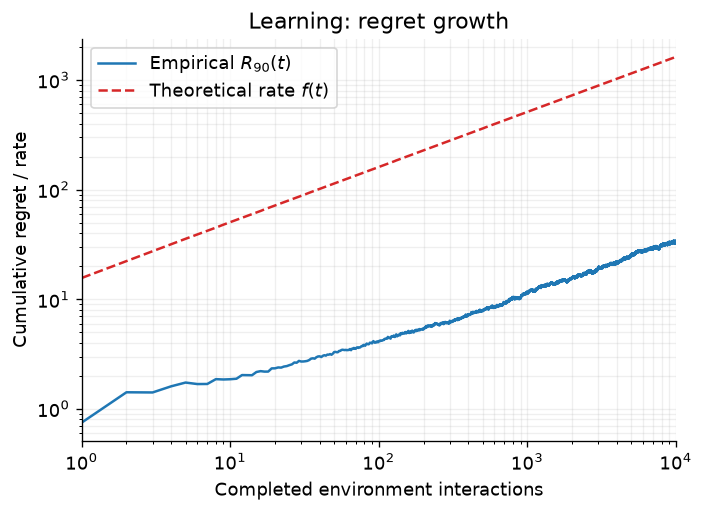

In [126]:
regret_times = np.arange(1, INTERACTIONS + 1)
empirical_q90 = np.quantile(gamma_regrets, 0.9, axis=0)
epochs = 2 + np.ceil(np.log2(regret_times))
log_factor = (np.log(16 * epochs / 0.05)
              + (1 + (LOOKAHEAD - 1) * NUM_STATES * NUM_ACTIONS) * np.log(NUM_STATES))
theoretical_rate = np.sqrt(regret_times * log_factor / (1 - DISCOUNT))

fig, ax = plt.subplots(figsize=(6, 4.4))
ax.loglog(regret_times, np.where(empirical_q90 > 0, empirical_q90, np.nan),
          color="tab:blue", label=r"Empirical $R_{90}(t)$")
ax.loglog(regret_times, theoretical_rate, "--", color="tab:red",
          label=r"Theoretical rate $f(t)$")
ax.set(xlabel="Completed environment interactions", ylabel="Cumulative regret / rate",
       title="Learning: regret growth", xlim=(1, INTERACTIONS))
ax.grid(which="both", alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

### Convergence to an optimal policy

Policy agreement is the unweighted fraction of **all** augmented states whose action
matches the offline oracle. Shading shows the pointwise 10th–90th percentiles across
runs, not confidence intervals. Curves are steps because policies
change only at doubling times. The final value error provides a separate performance check.

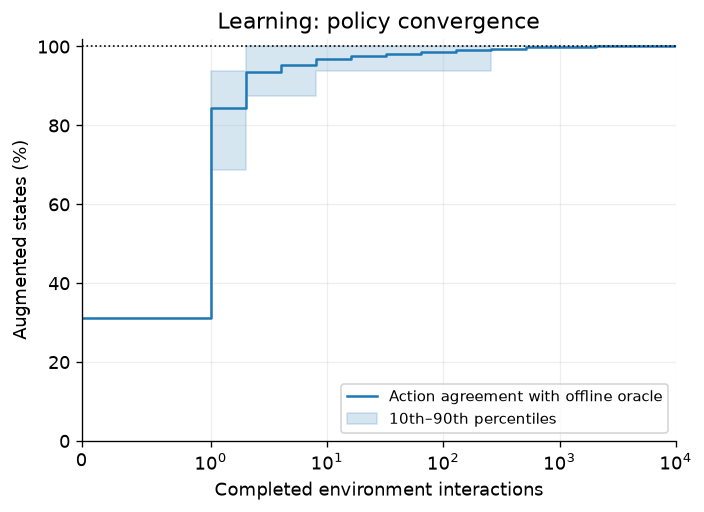

Final mean return: 7.452432070 (optimum: 7.452432070)
Largest final uniform value error: 8.447e-13
Final policies optimal on every augmented state: 1000/1000
Final policies identical to the offline oracle: 1000/1000


In [127]:
agreement = 100 * learning_metrics[:, :, 3]
low, high = np.quantile(agreement, [0.1, 0.9], axis=0)
fig, ax = plt.subplots(figsize=(6, 4.4))
ax.step(checkpoints, agreement.mean(axis=0), where="post", color="tab:blue",
        label="Action agreement with offline oracle")
ax.fill_between(checkpoints, low, high, step="post", color="tab:blue", alpha=0.18,
                label="10th–90th percentiles")
ax.axhline(100, color="black", linestyle=":", linewidth=1)
ax.set_xscale("symlog", linthresh=1)
ax.set(xlabel="Completed environment interactions", ylabel="Augmented states (%)",
       title="Learning: policy convergence", xlim=(0, INTERACTIONS), ylim=(0, 102))
ax.grid(alpha=0.2)
ax.legend(fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

final = learning_metrics[:, -1]
print(f"Final mean return: {final[:, 0].mean():.9f} (optimum: {OPTIMAL_RETURN:.9f})")
print(f"Largest final uniform value error: {final[:, 1].max():.3e}")
print(f"Final policies optimal on every augmented state: "
      f"{np.count_nonzero(final[:, 2] == 1)}/{LEARNING_REPEATS}")
print(f"Final policies identical to the offline oracle: "
      f"{np.count_nonzero(final[:, 3] == 1)}/{LEARNING_REPEATS}")

## Discount-factor sensitivity at fixed dictionary size

Keep the planning transition kernel and rewards fixed, with $\ell=2$ and a fixed dictionary size $N$.
For each discount, recompute the optimal augmented policy and RPTAS, and evaluate
both under the true law with the same uniform initial-state distribution.
The reported gap is
$$g(\gamma)=(1-\gamma)\,[J^*(\gamma)-J_{\mathrm{RPTAS}}(\gamma)].$$
The 120 dictionary draws are independent across repetitions and shared across
discounts. Error bars are normal-approximation 95% confidence intervals for the
mean normalized gap. Value iteration uses the shared numerical tolerance.

Theorem 2 gives a sufficient dictionary size of order
$\widetilde O(\ell|S||A|/[\varepsilon^2(1-\gamma)^4])$ for a uniform,
normalized value-error target. This fixed-$N$, initial-return experiment is a
descriptive sensitivity check; it does not estimate that worst-case exponent or
compare computational complexity with sparse sampling.

Completed 20/100 dictionaries.
Completed 40/100 dictionaries.
Completed 60/100 dictionaries.
Completed 80/100 dictionaries.
Completed 100/100 dictionaries.
N=16; 100 dictionaries (seeds 101--200); 100 shared evaluation conditions (seeds 10000--10099)
gamma | mean worst raw [q05, q95] | mean worst normalized [q05, q95]
0.50 | 0.00000000e+00 [0.00000000e+00, 0.00000000e+00] | 0.00000000e+00 [0.00000000e+00, 0.00000000e+00]
0.70 | 0.00000000e+00 [0.00000000e+00, 0.00000000e+00] | 0.00000000e+00 [0.00000000e+00, 0.00000000e+00]
0.80 | -1.88566224e-02 [-1.63573688e-01, 0.00000000e+00] | -3.77132447e-03 [-3.27147376e-02, 0.00000000e+00]
0.90 | -2.70933649e-02 [-6.22941334e-02, 0.00000000e+00] | -2.70933649e-03 [-6.22941334e-03, 0.00000000e+00]
0.95 | -3.55434510e-02 [-4.42391745e-01, 0.00000000e+00] | -1.77717255e-03 [-2.21195872e-02, 0.00000000e+00]
0.98 | -2.41568319e-02 [-1.50980199e-01, 0.00000000e+00] | -4.83136638e-04 [-3.01960399e-03, 0.00000000e+00]
0.99 | -2.51600586e-02 [-9.3185402

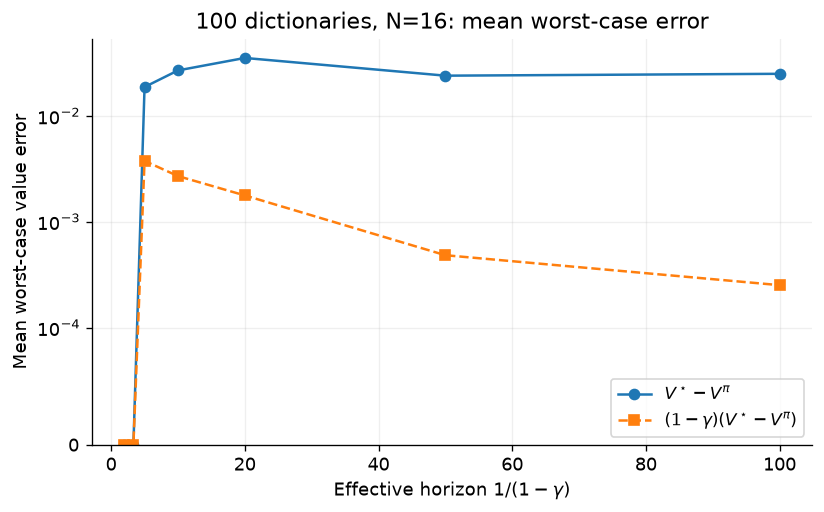

In [128]:
# Average the worst of 100 shared initial conditions over 100 dictionaries.
# Dictionary quantiles are retained in the table; the plot shows mean positive errors only.
AVERAGED_DISCOUNTS = np.array([0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99])
AVERAGED_DICTIONARY_SIZE = 16
AVERAGED_TRAIN_SEEDS = np.arange(101, 201)
AVERAGED_EVAL_SEEDS = np.arange(10_000, 10_100)
AVERAGED_QUANTILES = [0.05, 0.95]

assert LOOKAHEAD == 2
assert np.all((AVERAGED_DISCOUNTS > 0) & (AVERAGED_DISCOUNTS < 1))
assert len(np.unique(AVERAGED_TRAIN_SEEDS)) == len(AVERAGED_TRAIN_SEEDS)
assert len(np.unique(AVERAGED_EVAL_SEEDS)) == len(AVERAGED_EVAL_SEEDS)
assert not np.intersect1d(AVERAGED_TRAIN_SEEDS, AVERAGED_EVAL_SEEDS).size
averaged_run = {
    "discounts": AVERAGED_DISCOUNTS.copy(),
    "dictionary_size": AVERAGED_DICTIONARY_SIZE,
    "training_seeds": AVERAGED_TRAIN_SEEDS.copy(),
    "evaluation_seeds": AVERAGED_EVAL_SEEDS.copy(),
    "quantiles": np.array(AVERAGED_QUANTILES),
}

# Common initial augmented states for every dictionary and discount.
averaged_initial_conditions = np.empty((len(AVERAGED_EVAL_SEEDS), 3), dtype=int)
for evaluation, seed in enumerate(AVERAGED_EVAL_SEEDS):
    rng = np.random.default_rng(seed)
    state = rng.integers(NUM_STATES)
    first, second = rng.choice(NUM_TABLES, size=2, p=TRUE_WEIGHTS)
    averaged_initial_conditions[evaluation] = state, first, second
averaged_initial_indices = tuple(averaged_initial_conditions.T)

# The true oracle depends on gamma, but not on the sampled dictionary.
averaged_optimal_values = []
for discount in AVERAGED_DISCOUNTS:
    fit = solve_augmented(REWARDS, discount, TRUE_TABLES, TRUE_WEIGHTS)
    scores = augmented_scores(fit, REWARDS, discount, TRUE_TABLES, TRUE_WEIGHTS)
    _, optimal_values = evaluate_policy(greedy(scores), discount=discount)
    np.testing.assert_allclose(fit, optimal_values, atol=1e-9, rtol=0)
    averaged_optimal_values.append(optimal_values)
averaged_optimal_values = np.array(averaged_optimal_values)

averaged_dictionary_ids = np.empty(
    (len(AVERAGED_TRAIN_SEEDS), AVERAGED_DICTIONARY_SIZE), dtype=int,
)
averaged_eval_differences = np.empty(
    (len(AVERAGED_TRAIN_SEEDS), len(AVERAGED_EVAL_SEEDS), len(AVERAGED_DISCOUNTS)),
)
averaged_full_minimum = np.empty((len(AVERAGED_TRAIN_SEEDS), len(AVERAGED_DISCOUNTS)))

for repetition, seed in enumerate(AVERAGED_TRAIN_SEEDS):
    rng = np.random.default_rng(seed)
    ids = rng.choice(NUM_TABLES, size=AVERAGED_DICTIONARY_SIZE, p=TRUE_WEIGHTS)
    averaged_dictionary_ids[repetition] = ids
    tables, counts = np.unique(TRUE_TABLES[ids], axis=0, return_counts=True)
    weights = counts / AVERAGED_DICTIONARY_SIZE
    for column, discount in enumerate(AVERAGED_DISCOUNTS):
        # New value iteration from zero for each (dictionary, gamma) pair.
        planner = DictionaryPlanner(REWARDS, discount, tables, weights)
        _, values = evaluate_policy(dictionary_policy(planner), discount=discount)
        difference = values - averaged_optimal_values[column]
        assert difference.max() <= 1e-9
        averaged_eval_differences[repetition, :, column] = difference[averaged_initial_indices]
        averaged_full_minimum[repetition, column] = difference.min()
    if (repetition + 1) % 20 == 0:
        print(f"Completed {repetition + 1}/{len(AVERAGED_TRAIN_SEEDS)} dictionaries.", flush=True)

# First take the minimum over evaluation seeds, then average over dictionaries.
averaged_worst_raw = averaged_eval_differences.min(axis=1)
averaged_worst_normalized = averaged_worst_raw * (1 - AVERAGED_DISCOUNTS)[None, :]
averaged_worst_indices = averaged_eval_differences.argmin(axis=1)
averaged_worst_seeds = AVERAGED_EVAL_SEEDS[averaged_worst_indices]
assert np.all(np.isfinite(averaged_eval_differences))
assert np.all(averaged_worst_raw >= averaged_full_minimum - 1e-10)
np.testing.assert_allclose(
    (averaged_eval_differences * (1 - AVERAGED_DISCOUNTS)[None, None, :]).min(axis=1),
    averaged_worst_normalized, atol=0, rtol=0,
)

averaged_raw_mean = averaged_worst_raw.mean(axis=0)
averaged_raw_low, averaged_raw_high = np.quantile(
    averaged_worst_raw, AVERAGED_QUANTILES, axis=0,
)
averaged_normalized_mean = averaged_worst_normalized.mean(axis=0)
averaged_normalized_low, averaged_normalized_high = np.quantile(
    averaged_worst_normalized, AVERAGED_QUANTILES, axis=0,
)
print(f"N={AVERAGED_DICTIONARY_SIZE}; {len(AVERAGED_TRAIN_SEEDS)} dictionaries "
      f"(seeds {AVERAGED_TRAIN_SEEDS[0]}--{AVERAGED_TRAIN_SEEDS[-1]}); "
      f"{len(AVERAGED_EVAL_SEEDS)} shared evaluation conditions "
      f"(seeds {AVERAGED_EVAL_SEEDS[0]}--{AVERAGED_EVAL_SEEDS[-1]})")
print("gamma | mean worst raw [q05, q95] | mean worst normalized [q05, q95]")
for column, discount in enumerate(AVERAGED_DISCOUNTS):
    print(f"{discount:.2f} | {averaged_raw_mean[column]:.8e} "
          f"[{averaged_raw_low[column]:.8e}, {averaged_raw_high[column]:.8e}] | "
          f"{averaged_normalized_mean[column]:.8e} "
          f"[{averaged_normalized_low[column]:.8e}, {averaged_normalized_high[column]:.8e}]")

# Negate the signed means to display a positive error that rises with the loss.
averaged_raw_error = -averaged_raw_mean
averaged_normalized_error = -averaged_normalized_mean
assert np.all(averaged_raw_error >= -1e-10)
assert np.all(averaged_normalized_error >= -1e-10)
fig, ax = plt.subplots(figsize=(7, 4.4))
averaged_horizons = 1 / (1 - averaged_run["discounts"])
ax.plot(averaged_horizons, averaged_raw_error, "o-", color="tab:blue",
        label=r"$V^\star-V^\pi$")
ax.plot(averaged_horizons, averaged_normalized_error, "s--", color="tab:orange",
        label=r"$(1-\gamma)(V^\star-V^\pi)$")
# Logarithmic above 1e-4; linear near zero so optimal policies remain visible.
ax.set_yscale("symlog", linthresh=1e-4)
ax.set_ylim(bottom=0)
ax.set(xlabel=r"Effective horizon $1/(1-\gamma)$",
       ylabel="Mean worst-case value error",
       title=f"{len(AVERAGED_TRAIN_SEEDS)} dictionaries, N={AVERAGED_DICTIONARY_SIZE}: "
             "mean worst-case error")
ax.grid(which="both", alpha=0.2)
ax.legend(fontsize=10)
fig.tight_layout()
fig.savefig("gamma.pdf", bbox_inches="tight")
plt.show()